In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

FICHIER = "donnes.xltx"
f = 100    # fréquence echantillonnage (Hz)
dt = 1 / f # pas de temps (s)

In [6]:
# charger les données 

feuilles = ["X(t)", "Z(t)", "X target (t)", "Z target (t)"]
brut = {s: pd.read_excel(FICHIER, sheet_name=s, header=None).values for s in feuilles}

def charger_traj(j):
    # Renvoie un DataFrame pour la trajectoire j (0 à 5), sans les zéros de fin.
    z = brut["Z(t)"][:, j]
    n = np.nonzero(z)[0][-1] + 1                   # dernier échantillon non nul
    return pd.DataFrame({
        "x":  brut["X(t)"][:n, j],          "z":  brut["Z(t)"][:n, j],
        "xt": brut["X target (t)"][:n, j],  "zt": brut["Z target (t)"][:n, j],
    })

trajs = [charger_traj(j) for j in range(6)]
for j, d in enumerate(trajs):
    print(f"Traj {j+1}: {len(d)} échantillons ({len(d)/f:.2f} s) | "
          f"cible au départ = ({d.xt[0]:.1f}, {d.zt[0]:.1f})")

Traj 1: 255 échantillons (2.55 s) | cible au départ = (0.0, 59.9)
Traj 2: 222 échantillons (2.22 s) | cible au départ = (-25.3, 59.9)
Traj 3: 346 échantillons (3.46 s) | cible au départ = (0.0, 59.9)
Traj 4: 281 échantillons (2.81 s) | cible au départ = (-25.3, 59.9)
Traj 5: 453 échantillons (4.53 s) | cible au départ = (0.0, 59.9)
Traj 6: 382 échantillons (3.82 s) | cible au départ = (-25.3, 59.9)


In [10]:
def variables_exp(d):  # création fonction réutilisable => 6 fois
    d = d.copy()  # copie
    d["t"] = np.arange(len(d)) / f # création nouvelle colonne, np.arange = création suite puis divise par la f
    d["vx"] = d.x.diff() * f  # dérivation numéirque $\dot X_n = (X_n - X_{n-1}) \cdot f$., .diff() = fait la différencentre chaque ligne et sa précédente 
    d["vz"] = d.z.diff() * f
    d["v"] = np.hypot(d.vx, d.vz) # Pythagore = norme du vecteur, calcule $\sqrt{a^2 + b^2}$
    d["vxt"] = d.xt.diff() * f
    d["vzt"] = d.zt.diff() * f
    d["vt"] = np.hypot(d.vxt, d.vzt)
    d["phi"] = np.arctan2(d.vz, d.vx)  # direction de déplacement du sujet 
    d["theta"] = np.arctan2(d.zt - d.z, d.xt - d.x) # direction de la cible (bearing)
    d["beta"] = d.theta - d.phi  # angle cible-direction
    return d

exp = [variables_exp(d) for d in trajs] # on applique la fonction au 6 catégorie
exp[0].head()

,x,z,xt,zt,t,vx,vz,v,vxt,vzt,vt,phi,theta,beta
0,3.941412e-06,-0.042384,0.021399,59.895887,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.570439,NaN
1,3.365985e-06,0.171357,0.113941,59.842457,0.01,-0.000058,21.374096,21.374096,9.254209,-5.343089,10.685925,1.570799,1.568887,-0.001912
2,2.517138e-06,0.384537,0.206240,59.789166,0.02,-0.000085,21.317965,21.317965,9.229907,-5.329058,10.657863,1.570800,1.567325,-0.003476
3,1.356293e-06,0.596415,0.297976,59.736201,0.03,-0.000116,21.187834,21.187834,9.173570,-5.296530,10.592810,1.570802,1.565758,-0.005044
4,-1.411173e-07,0.806481,0.388927,59.683688,0.04,-0.000150,21.006598,21.006598,9.095110,-5.251228,10.502210,1.570803,1.564191,-0.006613


Vitesse sujet : 19.99 ± 0.19   |   vitesse cible : 10.00


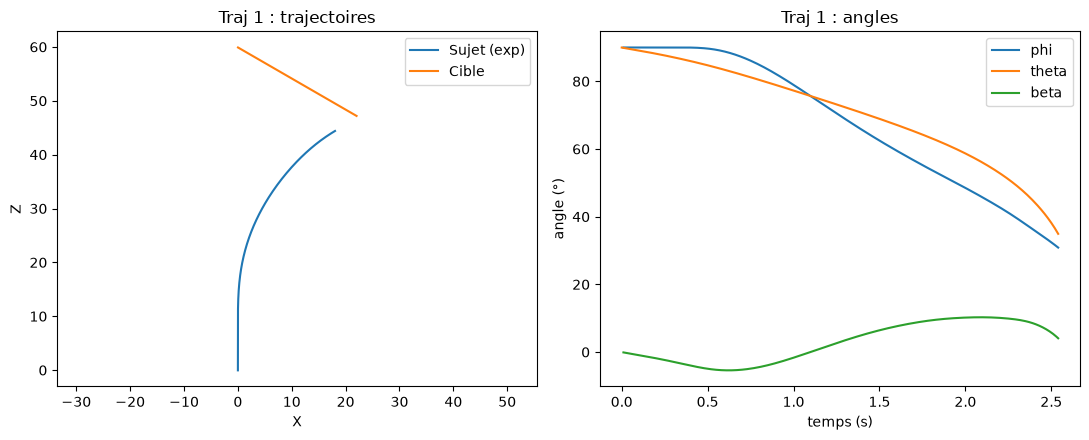

In [17]:
d = exp[0] # 1ère trajectoire indice 0
print(f"Vitesse sujet : {d.v.mean():.2f} ± {d.v.std():.2f}   |   vitesse cible : {d.vt.mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(d.x, d.z, label="Sujet (exp)") # chemin du sujet
ax[0].plot(d.xt, d.zt, label="Cible") # chemin de la cible
ax[0].set(xlabel="X", ylabel="Z", title="Traj 1 : trajectoires"); ax[0].axis("equal"); ax[0].legend()

# boucle sur les 3 colonnes d'angles = trace une courbe par angle

for col in ["phi", "theta", "beta"]:
    # temps en abscisse : angle converti de radians en degres en ordonnée
    ax[1].plot(d.t, np.degrees(d[col]), label=col)
ax[1].set(xlabel="temps (s)", ylabel="angle (°)", title="Traj 1 : angles"); ax[1].legend()
plt.tight_layout(); # aujustement automatique des marges
plt.show()






In [35]:
# Fonction de simulation => sujet virtuel qui attrape la cible

# d = tableau d'une trajectoire (on y prend la position de la cible)
# G = gain (raideur du "ressort")
# b = amortissement (damping)
# V = vitesse du sujet => par défaut 20
# delai = retard perceptif en secondes

def simuler(d, G, b, loi="beta", V=20.0, delai=0.0):
    '''Simule le sujet virtuel face à la cible de la trajectoire d.
    loi   : 'beta' (modèle 1), 'dbeta' (modèle 3) ou 'dtheta' (modèle 4)
    V     : vitesse du sujet (Vtot dans Excel)
    delai : délai perceptif en secondes (partie 7, 0 par défaut)'''

    # Positions réelles de la cible à chaque instant (colonnes T et U Excel)
    # .values => transforme la colonne pandas en tableau numpy
    xt, zt = d.xt.values, d.zt.values
    n = len(xt)  # nombre d'instants à simuler

    # Position du sujet simulé (X num et Z num, colonnes R/S)
    X, Z = np.zeros(n), np.zeros(n)

    # Direction φ, vitesse angulaire dφ/dt, accélération angulaire d²φ/dt²
    # (colonnes Y, Z et AA d'Excel)
    phi, dphi, ddphi = np.zeros(n), np.zeros(n), np.zeros(n)

    # Angles perçus : θ (direction de la cible) et β = θ − φ (colonnes AB et AD)
    theta, beta = np.zeros(n), np.zeros(n)

    # Conversion du délai en nombre de lignes : 0.1 s x 100 Hz = 10 lignes
    k = int(round(delai * f))

    # Initialisation (ligne 8 d'Excel)
    # Au départ, le sujet va tout droit vers +Z : φ = π/2 rad (90°)
    # (X et Z valent déjà 0 et dφ/dt aussi, grâce à np.zeros)
    phi[0] = np.pi / 2

    # Direction de la cible vue depuis la position de départ du sujet
    theta[0] = np.arctan2(zt[0] - Z[0], xt[0] - X[0])

    # Écart entre la direction de la cible et celle du sujet
    beta[0] = theta[0] - phi[0]

    # Fonction information perçue
    def info(i):
        # Avec un délai, le sujet utilise l'information d'il y a k lignes
        # max(..., 0) empêche d'aller chercher une ligne négative au début
        i = max(i - k, 0)

        # Modèle 1 (poursuite) : l'information est β
        if loi == "beta":
            return beta[i]

        # Modèle 3 : information dβ/dt, dérivée numérique (β_i − β_i-1) × f
        if loi == "dbeta":
            return (beta[i] - beta[i-1]) * f if i > 0 else 0.0

        # Modèle 4 (constant bearing) : information dθ/dt
        if loi == "dtheta":
            return (theta[i] - theta[i-1]) * f if i > 0 else 0.0

    # Loi de contrôle au temps 0 : d²φ/dt² = G × information − b × dφ/dt
    ddphi[0] = G * info(0) - b * dphi[0]

    # Boucle temps (lignes 9 et suivantes d'Excel)
    # i prend les valeurs 1, 2, ..., n-1 : chaque tour = 1 instant = 0.01 s
    for i in range(1, n):

        # 1) Intégration : nouvelle vitesse angulaire = ancienne + accélération x dt
        # (colonne Z : "V Phi num")
        dphi[i] = dphi[i-1] + ddphi[i-1] * dt

        # 2) Intégration : nouvelle direction = ancienne + vitesse angulaire x dt
        # (colonne Y : "Phi num")
        phi[i] = phi[i-1] + dphi[i] * dt

        # 3) Déplacement : le sujet avance à la vitesse V dans la direction φ
        # composante X de la vitesse = V.cos φ, puis X_n = X_n-1 + Vx.dt (colonnes W/R)
        X[i] = X[i-1] + V * np.cos(phi[i]) * dt
        # composante Z de la vitesse = V.sin φ, puis Z_n = Z_n-1 + Vz.dt (colonnes X/S)
        Z[i] = Z[i-1] + V * np.sin(phi[i]) * dt

        # 4) Perception : où le sujet voit-il la cible depuis sa nouvelle position ?
        # (colonne AB : "Théta num")
        theta[i] = np.arctan2(zt[i] - Z[i], xt[i] - X[i])

        # Écart cible-direction (colonne AD : "Beta")
        beta[i] = theta[i] - phi[i]

        # 5) Décision : loi de contrôle, calcul de l'accélération angulaire
        # utilisée au tour suivant (colonne AA : "A Phi num")
        ddphi[i] = G * info(i) - b * dphi[i]

    # Sortie : rassemble tous les résultats dans un tableau pandas
    return pd.DataFrame({"X": X, "Z": Z, "phi": phi, "dphi": dphi,
                         "theta": theta, "beta": beta})




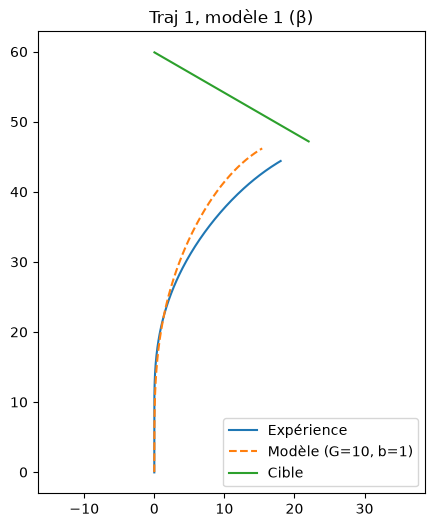

In [36]:
# Lancer la simulation sur la trajectoire 1 et stocke le résutlat dans 'sim'
sim = simuler(exp[0], G=10, b=1, loi="beta")

# création figure 
plt.figure(figsize=(5,6))
plt.plot(exp[0].x, exp[0].z, label="Expérience")
plt.plot(sim.X, sim.Z, "--", label="Modèle (G=10, b=1)")
plt.plot(exp[0].xt, exp[0].zt, label="Cible")
plt.axis("equal")
plt.legend()
plt.title("Traj 1, modèle 1 (β)")
plt.show()



